# 03. SQL Analysis of Delay Patterns

This notebook:

1. Compares average delay by carrier and by route.
2. Ranks carriers overall and within each route, limited to routes where carriers actually compete.
3. Runs a Pareto analysis of delay causes, nationally and on the worst routes.
4. Measures route variability with the standard deviation and percentiles.
5. Computes punctuality rates and separates how often a carrier is late from how late it is.
6. Follows each aircraft through its daily rotation to measure how delays propagate.
7. Looks for bottleneck airports through taxi-out times.
8. Checks punctuality by scheduled hour and finds the most disrupted days of the year.

**Scope.** Descriptive SQL on `staging.stg_bts_flights`. No modelling, and nothing here establishes causal effects.

**Prerequisites.** The staging table loaded and validated in Notebook 02, and the same `.env` in the project root.

# 1. Environment setup

This notebook only reads from PostgreSQL. Queries are plain SQL strings, read into pandas for display and the occasional chart.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import logging
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger(__name__)

PROJECT_ROOT = Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")

DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with engine.connect() as conn:
    result = conn.execute(text("SELECT current_database();"))
    logger.info(f"Connected to database: {result.scalar()}")

2026-10-27 09:50:16,083 - INFO - Connected to database: bts_flights_db


# 2. Average delay by carrier and route

I report departure delay (`dep_delay`) and arrival delay (`arr_delay`) separately. A flight can leave late and recover in the air, or leave on time and arrive late.

Cancelled flights are filtered out with `WHERE cancelled = 0`. `AVG()` would skip their nulls anyway, but I prefer the exclusion to be visible in the query. For routes I require at least 100 flights so that routes with a handful of flights don't produce meaningless averages.

In [2]:
query_delay_by_carrier = """
SELECT
    reporting_airline,
    COUNT(*) AS total_flights,
    ROUND(AVG(dep_delay)::numeric, 2) AS avg_dep_delay,
    ROUND(AVG(arr_delay)::numeric, 2) AS avg_arr_delay
FROM staging.stg_bts_flights
WHERE cancelled = 0
GROUP BY reporting_airline
ORDER BY avg_arr_delay DESC;
"""

with engine.connect() as conn:
    df_delay_by_carrier = pd.read_sql(text(query_delay_by_carrier), conn)

df_delay_by_carrier

,reporting_airline,total_flights,avg_dep_delay,avg_arr_delay
0,AA,969054,20.65,15.31
1,F9,203789,18.95,15.25
2,B6,236547,17.40,10.74
3,OH,224220,13.87,10.03
4,G4,115192,14.04,9.71
5,NK,256105,14.92,8.42
6,OO,736131,11.27,7.36
7,MQ,275970,10.14,6.46
8,UA,747973,11.91,5.74
9,WN,1407647,11.74,5.13


**AA** has the highest average arrival delay (15.31 min), and **F9** is practically tied (15.25 min) with about a fifth of AA's volume. At the other end, **DL** is the most punctual of the carriers with more than 500K flights (3.66 min), and **YX** has a negative average, meaning its flights arrive slightly early on average.

Every carrier arrives with less delay than it departs, by roughly 1 to 7 minutes. That fits schedule padding: block times include a buffer that absorbs part of the departure delay.

In [3]:
query_delay_by_route = """
SELECT
    origin,
    dest,
    COUNT(*) AS total_flights,
    ROUND(AVG(dep_delay)::numeric, 2) AS avg_dep_delay,
    ROUND(AVG(arr_delay)::numeric, 2) AS avg_arr_delay
FROM staging.stg_bts_flights
WHERE cancelled = 0
GROUP BY origin, dest
HAVING COUNT(*) >= 100
ORDER BY avg_arr_delay DESC
LIMIT 20;
"""

with engine.connect() as conn:
    df_delay_by_route = pd.read_sql(text(query_delay_by_route), conn)

df_delay_by_route

,origin,dest,total_flights,avg_dep_delay,avg_arr_delay
0,RDM,DFW,130,90.90,87.43
1,EGE,MIA,129,68.24,75.30
2,RNO,JFK,117,74.23,73.79
3,DFW,RDM,130,63.92,62.96
4,IDA,LAS,109,57.92,59.61
5,SNA,MIA,190,67.11,57.31
6,JAC,DFW,611,61.56,56.27
7,EGE,JFK,104,55.79,56.23
8,ANC,ATL,105,59.37,56.11
9,MSO,LAS,116,55.60,55.47


The worst routes cluster around small regional and resort airports such as RDM (Bend, OR), EGE (Eagle/Vail, CO) and JAC (Jackson Hole, WY). Averages reach 87 minutes on RDM→DFW, far above any carrier average, on routes with only 100 to 600 flights in the year. Winter weather at mountain airports is a plausible explanation, which I test in Section 4.1.

# 3. Carrier ranking, overall and within route

A global ranking tells which carrier is worst overall. It doesn't tell which carrier is worst on a specific route, which is the question a traveller or a network planner actually faces. `RANK() OVER (PARTITION BY origin, dest ...)` answers that second one.

In [4]:
query_carrier_rank_global = """
SELECT
    reporting_airline,
    COUNT(*) AS total_flights,
    ROUND(AVG(arr_delay)::numeric, 2) AS avg_arr_delay,
    RANK() OVER (ORDER BY AVG(arr_delay) DESC) AS delay_rank
FROM staging.stg_bts_flights
WHERE cancelled = 0
GROUP BY reporting_airline
ORDER BY delay_rank;
"""

with engine.connect() as conn:
    df_carrier_rank_global = pd.read_sql(text(query_carrier_rank_global), conn)

df_carrier_rank_global

,reporting_airline,total_flights,avg_arr_delay,delay_rank
0,AA,969054,15.31,1
1,F9,203789,15.25,2
2,B6,236547,10.74,3
3,OH,224220,10.03,4
4,G4,115192,9.71,5
5,NK,256105,8.42,6
6,OO,736131,7.36,7
7,MQ,275970,6.46,8
8,UA,747973,5.74,9
9,WN,1407647,5.13,10


AA ranks first (worst) across nearly a million flights, so it isn't a small-sample effect. DL is 13th, the best of the large carriers, and WN lands mid-table (10th) despite being the largest carrier by volume.

In [5]:
query_carrier_rank_by_route = """
WITH route_carrier_delay AS (
    SELECT
        origin,
        dest,
        reporting_airline,
        COUNT(*) AS total_flights,
        AVG(arr_delay) AS avg_arr_delay
    FROM staging.stg_bts_flights
    WHERE cancelled = 0
    GROUP BY origin, dest, reporting_airline
    HAVING COUNT(*) >= 100
),
ranked AS (
    SELECT
        *,
        RANK() OVER (PARTITION BY origin, dest ORDER BY avg_arr_delay DESC) AS worst_rank
    FROM route_carrier_delay
)
SELECT
    origin,
    dest,
    reporting_airline,
    total_flights,
    ROUND(avg_arr_delay::numeric, 2) AS avg_arr_delay
FROM ranked
WHERE worst_rank = 1
ORDER BY avg_arr_delay DESC
LIMIT 20;
"""

with engine.connect() as conn:
    df_carrier_rank_by_route = pd.read_sql(text(query_carrier_rank_by_route), conn)

df_carrier_rank_by_route

,origin,dest,reporting_airline,total_flights,avg_arr_delay
0,RDM,DFW,AA,130,87.43
1,CLT,AVL,AA,241,79.01
2,EGE,MIA,AA,129,75.30
3,RNO,JFK,B6,117,73.79
4,PDX,ORD,NK,102,67.53
5,DFW,RDM,AA,130,62.96
6,MIA,SAV,AA,114,62.95
7,EGE,ORD,AA,102,62.22
8,SLC,DFW,F9,125,60.14
9,AUS,DFW,OO,121,59.81


At first sight AA dominates this list, with 13 of the 20 rows. Before treating that as a finding I noticed a problem with the query: `RANK()` gives rank 1 to the only carrier on a route, so on single-carrier routes being "the worst" is automatic. Many of these routes connect a small airport with an AA hub (DFW, CLT, MIA), where AA is probably the only operator.

The corrected version counts the carriers on each route with `COUNT(*) OVER (PARTITION BY origin, dest)` and keeps routes with at least two. It also measures how far the worst carrier is from the best one on the same route, which is a fairer way to sort.

In [6]:
contested_routes_cte = """
WITH route_carrier_delay AS (
    SELECT
        origin,
        dest,
        reporting_airline,
        COUNT(*) AS total_flights,
        AVG(arr_delay) AS avg_arr_delay
    FROM staging.stg_bts_flights
    WHERE cancelled = 0
    GROUP BY origin, dest, reporting_airline
    HAVING COUNT(*) >= 100
),
ranked AS (
    SELECT
        *,
        COUNT(*) OVER (PARTITION BY origin, dest) AS n_carriers,
        RANK() OVER (PARTITION BY origin, dest ORDER BY avg_arr_delay DESC) AS worst_rank,
        MIN(avg_arr_delay) OVER (PARTITION BY origin, dest) AS best_on_route
    FROM route_carrier_delay
)
"""

query_worst_on_contested_routes = contested_routes_cte + """
SELECT
    origin,
    dest,
    reporting_airline AS worst_carrier,
    n_carriers,
    total_flights,
    ROUND(avg_arr_delay::numeric, 2) AS avg_arr_delay,
    ROUND((avg_arr_delay - best_on_route)::numeric, 2) AS gap_vs_best_carrier
FROM ranked
WHERE worst_rank = 1
  AND n_carriers >= 2
ORDER BY gap_vs_best_carrier DESC
LIMIT 20;
"""

with engine.connect() as conn:
    df_worst_contested = pd.read_sql(text(query_worst_on_contested_routes), conn)

df_worst_contested

,origin,dest,worst_carrier,n_carriers,total_flights,avg_arr_delay,gap_vs_best_carrier
0,CLT,AVL,AA,3,241,79.01,72.20
1,PDX,ORD,NK,4,102,67.53,71.71
2,MIA,SAV,AA,2,114,62.95,61.97
3,DTW,ORD,AA,7,336,52.02,57.20
4,MSP,PHL,F9,4,112,56.58,56.04
5,PHL,SLC,AA,2,116,56.65,54.74
6,DFW,LBB,AA,3,414,55.72,52.50
7,SLC,DFW,F9,3,125,60.14,51.59
8,BOS,SJU,F9,4,110,51.68,51.07
9,PDX,BOS,B6,2,177,48.89,48.42


A single list still favours carriers that fly many contested routes. The summary below shows, for each carrier, on how many contested routes it operates and on what share of them it is the worst. On a route with two carriers, the chance of being last is already 50%, so the share needs a baseline. For each carrier I compute the share it would get by pure chance, the average of 1/n over its contested routes, where n is the number of carriers on the route. Averaging 1/n route by route matters: 1 divided by the average number of carriers gives a lower figure, because routes with two carriers weigh more than routes with five.

In [7]:
query_worst_share_by_carrier = contested_routes_cte + """
SELECT
    reporting_airline,
    COUNT(*) AS contested_routes,
    COUNT(*) FILTER (WHERE worst_rank = 1) AS routes_where_worst,
    ROUND(100.0 * COUNT(*) FILTER (WHERE worst_rank = 1) / COUNT(*), 1) AS pct_routes_where_worst,
    ROUND(AVG(n_carriers)::numeric, 2) AS avg_competitors_per_route,
    ROUND(100.0 * AVG(1.0 / n_carriers), 1) AS expected_pct_by_chance,
    ROUND((COUNT(*) FILTER (WHERE worst_rank = 1)::numeric / COUNT(*)) / AVG(1.0 / n_carriers), 2) AS observed_to_expected
FROM ranked
WHERE n_carriers >= 2
GROUP BY reporting_airline
ORDER BY pct_routes_where_worst DESC;
"""

with engine.connect() as conn:
    df_worst_share = pd.read_sql(text(query_worst_share_by_carrier), conn)

df_worst_share

,reporting_airline,contested_routes,routes_where_worst,pct_routes_where_worst,avg_competitors_per_route,expected_pct_by_chance,observed_to_expected
0,HA,62,47,75.8,2.55,42.7,1.77
1,AA,713,453,63.5,3.10,36.8,1.73
2,F9,515,323,62.7,3.36,33.0,1.90
3,B6,263,157,59.7,3.03,36.8,1.62
4,G4,40,22,55.0,2.15,47.5,1.16
5,OO,683,283,41.4,2.97,37.8,1.10
6,OH,250,101,40.4,2.72,40.3,1.00
7,AS,202,80,39.6,2.93,39.3,1.01
8,NK,486,171,35.2,3.19,35.3,1.00
9,WN,771,235,30.5,2.88,38.9,0.78


Once single-carrier routes are gone, AA still stands out. It flies 713 contested routes, and by chance alone it would be the worst on 36.8% of them; it's the worst on 63.5%, about 1.7 times that. F9 shows a stronger version of the same pattern (62.7% against 33.0% expected, 1.9 times, across 515 routes). At the other end, DL (21.0% against 37.2%) and YX (12.9% against 37.4%) are the worst far less often than chance would predict. HA has the highest share (75.8% against 42.7%), but on only 62 routes.

The first table shows where the choice of airline matters most on the same route. On CLT→AVL, AA averages 72 minutes more arrival delay than the best carrier on that route, and on PDX→ORD, NK is 72 minutes behind.

# 4. Delay-cause Pareto analysis

BTS reports delay causes (`carrier_delay`, `weather_delay`, `nas_delay`, `security_delay`, `late_aircraft_delay`) as minutes attributed to each cause, filled only when a flight arrived 15+ minutes late (`arr_del15 = 1`).

I sum minutes per cause instead of counting flights with a non-zero value. Many flights delayed a few minutes each and a few flights delayed for hours are different problems, and minutes capture the real operational cost.

Each cause lives in its own column, so a `UNION ALL` turns them into rows. A windowed `SUM() OVER (ORDER BY total_minutes DESC)` then gives the running cumulative share.

In [8]:
query_delay_pareto = """
SELECT
    cause,
    total_minutes,
    ROUND((100.0 * total_minutes / SUM(total_minutes) OVER ())::numeric, 2) AS pct_of_total,
    ROUND((100.0 * SUM(total_minutes) OVER (ORDER BY total_minutes DESC) 
        / SUM(total_minutes) OVER ())::numeric, 2) AS cumulative_pct
FROM (
    SELECT 'Carrier' AS cause, SUM(carrier_delay::double precision) AS total_minutes
    FROM staging.stg_bts_flights WHERE arr_del15 = 1
    UNION ALL
    SELECT 'Weather', SUM(weather_delay::double precision)
    FROM staging.stg_bts_flights WHERE arr_del15 = 1
    UNION ALL
    SELECT 'NAS', SUM(nas_delay::double precision)
    FROM staging.stg_bts_flights WHERE arr_del15 = 1
    UNION ALL
    SELECT 'Security', SUM(security_delay::double precision)
    FROM staging.stg_bts_flights WHERE arr_del15 = 1
    UNION ALL
    SELECT 'Late Aircraft', SUM(late_aircraft_delay::double precision)
    FROM staging.stg_bts_flights WHERE arr_del15 = 1
) AS cause_totals
ORDER BY total_minutes DESC;
"""

with engine.connect() as conn:
    df_delay_pareto = pd.read_sql(text(query_delay_pareto), conn)

df_delay_pareto

,cause,total_minutes,pct_of_total,cumulative_pct
0,Late Aircraft,41973684.0,40.44,40.44
1,Carrier,35823263.0,34.51,74.95
2,NAS,19621964.0,18.90,93.86
3,Weather,6195873.0,5.97,99.83
4,Security,179928.0,0.17,100.00


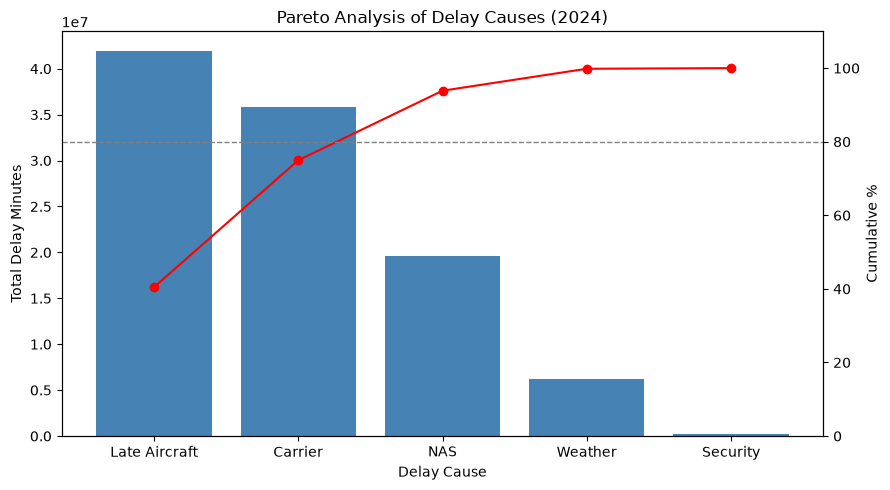

In [9]:
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.bar(df_delay_pareto["cause"], df_delay_pareto["total_minutes"], color="steelblue")
ax1.set_ylabel("Total Delay Minutes")
ax1.set_xlabel("Delay Cause")

ax2 = ax1.twinx()
ax2.plot(df_delay_pareto["cause"], df_delay_pareto["cumulative_pct"], color="red", marker="o")
ax2.set_ylabel("Cumulative %")
ax2.set_ylim(0, 110)
ax2.axhline(80, color="gray", linestyle="--", linewidth=1)

plt.title("Pareto Analysis of Delay Causes (2024)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_delay_cause_pareto.png", dpi=150)
plt.show()

Delay minutes are concentrated in a few causes. **Late Aircraft** (40.44%) and **Carrier** (34.51%) add up to 74.95%, and **NAS** (18.90%) brings the cumulative share to 93.86%. **Weather** (5.97%) and **Security** (0.17%) are small at the national level.

With only five categories this is a coarse Pareto, but the ordering says something. Late Aircraft at the top means delays cascade: one plane flies several legs a day, so a morning delay can show up hours later on a different route. Section 7 measures that directly.

Two caveats. The airlines report the causes themselves, and BTS files non-extreme weather under NAS, so the 6% weather share understates the real weight of weather.

## 4.1 Causes on the worst routes

Section 2 left a hypothesis open: are the extreme averages on resort routes driven by weather? The national Pareto can't answer that because it mixes every flight. Here I repeat the cause breakdown for six of the worst routes from Section 2.

In [10]:
query_route_causes = """
WITH route_causes AS (
    SELECT
        origin,
        dest,
        COUNT(*) AS delayed_flights,
        SUM(carrier_delay::double precision) AS carrier,
        SUM(weather_delay::double precision) AS weather,
        SUM(nas_delay::double precision) AS nas,
        SUM(security_delay::double precision) AS security,
        SUM(late_aircraft_delay::double precision) AS late_aircraft
    FROM staging.stg_bts_flights
    WHERE arr_del15 = 1
      AND (origin, dest) IN (('RDM', 'DFW'), ('EGE', 'MIA'), ('RNO', 'JFK'),
                             ('JAC', 'DFW'), ('EGE', 'JFK'), ('HDN', 'DFW'))
    GROUP BY origin, dest
),
totals AS (
    SELECT *, (carrier + weather + nas + security + late_aircraft) AS total_minutes
    FROM route_causes
)
SELECT
    origin,
    dest,
    delayed_flights,
    ROUND((100.0 * carrier / total_minutes)::numeric, 1) AS pct_carrier,
    ROUND((100.0 * weather / total_minutes)::numeric, 1) AS pct_weather,
    ROUND((100.0 * nas / total_minutes)::numeric, 1) AS pct_nas,
    ROUND((100.0 * late_aircraft / total_minutes)::numeric, 1) AS pct_late_aircraft
FROM totals
ORDER BY pct_weather DESC;
"""

with engine.connect() as conn:
    df_route_causes = pd.read_sql(text(query_route_causes), conn)

df_route_causes

,origin,dest,delayed_flights,pct_carrier,pct_weather,pct_nas,pct_late_aircraft
0,JAC,DFW,191,21.8,4.1,12.2,61.8
1,RDM,DFW,63,22.1,3.2,4.1,70.5
2,HDN,DFW,63,28.8,1.6,11.9,57.6
3,EGE,MIA,70,40.2,0.9,13.3,45.6
4,EGE,JFK,42,47.7,0.3,10.5,41.4
5,RNO,JFK,44,69.3,0.0,7.0,23.7


The weather hypothesis doesn't hold. On these six routes weather accounts for 0 to 4% of delay minutes and NAS for 4 to 13%, so even together they stay below the national 25%. What dominates is Late Aircraft (24 to 71%) and Carrier (22 to 69%). Four of the six routes end at DFW or MIA, both AA hubs, which points to aircraft rotations and airline operations more than to mountain weather.

Each route has only 42 to 191 delayed flights, so the shares are rough, but the pattern repeats on all six.

# 5. Route variability

An average hides how predictable a route is. Two routes with the same mean can differ completely in spread, and the high-spread one is riskier for a tight connection. `STDDEV(arr_delay)` measures that.

The CTE separates the aggregation (mean and standard deviation per route) from the ordering, the same two-step structure used in Section 3.

In [11]:
query_route_variability = """
WITH route_stats AS (
    SELECT
        origin,
        dest,
        COUNT(*) AS total_flights,
        ROUND(AVG(arr_delay)::numeric, 2) AS avg_arr_delay,
        ROUND(STDDEV(arr_delay)::numeric, 2) AS stddev_arr_delay
    FROM staging.stg_bts_flights
    WHERE cancelled = 0
    GROUP BY origin, dest
    HAVING COUNT(*) >= 100
)
SELECT *
FROM route_stats
ORDER BY stddev_arr_delay DESC
LIMIT 20;
"""

with engine.connect() as conn:
    df_route_variability = pd.read_sql(text(query_route_variability), conn)

df_route_variability

,origin,dest,total_flights,avg_arr_delay,stddev_arr_delay
0,RNO,JFK,117,73.79,274.10
1,JAC,DFW,611,56.27,248.65
2,STX,MIA,622,38.93,225.39
3,EGE,MIA,129,75.30,222.43
4,RDM,DFW,130,87.43,221.92
5,SNA,MIA,190,57.31,214.81
6,HDN,DFW,184,49.46,212.42
7,JAC,CLT,122,46.02,208.21
8,EGE,JFK,104,56.23,202.44
9,RAP,CLT,121,51.16,202.28


The same regional and resort routes show up again, now with standard deviations of 180–274 minutes against means of 25–87. A standard deviation several times the mean suggests that a few extreme events pull the averages up while most flights run close to on time.

That's still a hypothesis. The standard deviation alone can't tell a few huge outliers apart from a broadly spread distribution, so the next query adds the median, the 90th percentile and the maximum.

In [12]:
query_route_percentiles = """
WITH route_stats AS (
    SELECT
        origin,
        dest,
        COUNT(*) AS total_flights,
        AVG(arr_delay) AS avg_arr_delay,
        STDDEV(arr_delay) AS stddev_arr_delay,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY arr_delay) AS median_arr_delay,
        PERCENTILE_CONT(0.9) WITHIN GROUP (ORDER BY arr_delay) AS p90_arr_delay,
        MAX(arr_delay) AS max_arr_delay
    FROM staging.stg_bts_flights
    WHERE cancelled = 0
      AND arr_delay IS NOT NULL
    GROUP BY origin, dest
    HAVING COUNT(*) >= 100
)
SELECT
    origin,
    dest,
    total_flights,
    ROUND(avg_arr_delay::numeric, 1) AS avg_arr_delay,
    ROUND(median_arr_delay::numeric, 1) AS median_arr_delay,
    ROUND(p90_arr_delay::numeric, 1) AS p90_arr_delay,
    ROUND(max_arr_delay::numeric, 0) AS max_arr_delay,
    ROUND(stddev_arr_delay::numeric, 1) AS stddev_arr_delay
FROM route_stats
ORDER BY stddev_arr_delay DESC
LIMIT 20;
"""

with engine.connect() as conn:
    df_route_percentiles = pd.read_sql(text(query_route_percentiles), conn)

df_route_percentiles

,origin,dest,total_flights,avg_arr_delay,median_arr_delay,p90_arr_delay,max_arr_delay,stddev_arr_delay
0,RNO,JFK,117,73.8,3.0,111.0,1596.0,274.1
1,JAC,DFW,608,56.3,-4.0,98.2,2700.0,248.7
2,STX,MIA,620,38.9,-2.0,60.4,2899.0,225.4
3,EGE,MIA,128,75.3,19.5,126.6,1311.0,222.4
4,RDM,DFW,128,87.4,14.0,177.3,1380.0,221.9
5,SNA,MIA,189,57.3,-10.0,117.4,1151.0,214.8
6,HDN,DFW,182,49.5,1.0,86.0,1561.0,212.4
7,JAC,CLT,121,46.0,9.0,92.0,1774.0,208.2
8,EGE,JFK,102,56.2,5.5,123.5,1521.0,202.4
9,RAP,CLT,121,51.2,9.0,60.0,1508.0,202.3


For most of these routes the reading holds. The median arrival delay sits between −14 and +9 minutes on 18 of the 20, so a typical flight arrives close to on time, while the maximums run from about 1,070 to 2,900 minutes. A handful of extreme events, some of them delays of more than a day, inflate both the mean and the standard deviation.

Two routes are different. EGE→MIA (median 19.5 min) and RDM→DFW (median 14 min) are late on a typical day too, with 90th percentiles of 127 and 177 minutes. Those are chronically late, on top of being volatile.

# 6. Punctuality rate

BTS defines a delayed flight as one arriving 15 or more minutes late and ships it as the flag `arr_del15`. I use the flag directly so the definition matches the official one.

`arr_del15` is null for both cancelled and diverted flights, since neither has a measurable arrival delay. In a first version I divided by all non-cancelled flights, which left diverted flights in the denominator counted as "not delayed". The queries below follow BTS's own breakdown: every scheduled flight is on time, delayed, cancelled or diverted, and the delay rate is computed over flights that actually arrived (`arr_del15 IS NOT NULL`).

In [13]:
query_punctuality_overall = """
SELECT
    COUNT(*) AS scheduled_flights,
    COUNT(*) FILTER (WHERE arr_del15 = 0) AS on_time_flights,
    COUNT(*) FILTER (WHERE arr_del15 = 1) AS delayed_flights,
    COUNT(*) FILTER (WHERE cancelled = 1) AS cancelled_flights,
    COUNT(*) FILTER (WHERE diverted = 1) AS diverted_flights,
    ROUND(100.0 * COUNT(*) FILTER (WHERE cancelled = 1) / COUNT(*), 2) AS pct_cancelled,
    ROUND(100.0 * COUNT(*) FILTER (WHERE diverted = 1) / COUNT(*), 2) AS pct_diverted,
    ROUND(100.0 * COUNT(*) FILTER (WHERE arr_del15 = 1)
        / COUNT(*) FILTER (WHERE arr_del15 IS NOT NULL), 2) AS pct_delayed_of_arrived
FROM staging.stg_bts_flights;
"""

with engine.connect() as conn:
    df_punctuality_overall = pd.read_sql(text(query_punctuality_overall), conn)

df_punctuality_overall

,scheduled_flights,on_time_flights,delayed_flights,cancelled_flights,diverted_flights,pct_cancelled,pct_diverted,pct_delayed_of_arrived
0,7079061,5515281,1449966,96315,17499,1.36,0.25,20.82


Out of 7,079,061 scheduled flights, 5,515,281 arrived on time, 1,449,966 were delayed, 96,315 were cancelled (1.36%) and 17,499 were diverted (0.25%). Among flights that arrived, **20.82%** were 15+ minutes late, one in five. The first version gave 20.76% because diverted flights sat in the denominator. A small change, but the four categories now add up exactly to the total.

In [14]:
query_punctuality_by_carrier = """
SELECT
    reporting_airline,
    COUNT(*) FILTER (WHERE arr_del15 IS NOT NULL) AS arrived_flights,
    ROUND(100.0 * COUNT(*) FILTER (WHERE arr_del15 = 1)
        / COUNT(*) FILTER (WHERE arr_del15 IS NOT NULL), 2) AS pct_delayed,
    ROUND(100.0 * COUNT(*) FILTER (WHERE cancelled = 1) / COUNT(*), 2) AS pct_cancelled
FROM staging.stg_bts_flights
GROUP BY reporting_airline
ORDER BY pct_delayed DESC;
"""

with engine.connect() as conn:
    df_punctuality_by_carrier = pd.read_sql(text(query_punctuality_by_carrier), conn)

df_punctuality_by_carrier

,reporting_airline,arrived_flights,pct_delayed,pct_cancelled
0,F9,203482,28.74,2.32
1,AA,966116,26.13,1.55
2,B6,235683,25.51,1.55
3,NK,255633,23.93,1.91
4,AS,240323,22.07,1.96
5,OH,223673,21.77,1.65
6,G4,114882,21.67,1.72
7,MQ,275317,20.86,1.42
8,WN,1404597,20.60,0.83
9,UA,745818,19.86,1.64


The delay rate doesn't rank carriers the same way as the mean delay. **F9** is late most often (28.74% of its arrived flights), ahead of **AA** (26.13%), which had the highest mean delay in Section 2. **DL** stays among the best on both measures (17.26%), **WN** sits right at the national rate (20.60% vs 20.82%), and **YX** is the most punctual (14.07%).

It's tempting to say that F9 is late more often while AA's delays are longer. The mean from Section 2 can't support that, though: it averages every arrived flight, early arrivals included, so it mixes how often a carrier is late with how late it is. To compare the length of delays I need the average conditional on being delayed.

## 6.1 Delay severity when a delay happens

In [15]:
query_severity_by_carrier = """
SELECT
    reporting_airline,
    COUNT(*) FILTER (WHERE arr_del15 = 1) AS delayed_flights,
    ROUND((AVG(arr_delay) FILTER (WHERE arr_del15 = 1))::numeric, 1) AS avg_delay_when_delayed,
    ROUND((PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY arr_delay)
        FILTER (WHERE arr_del15 = 1))::numeric, 1) AS median_delay_when_delayed
FROM staging.stg_bts_flights
GROUP BY reporting_airline
ORDER BY avg_delay_when_delayed DESC;
"""

with engine.connect() as conn:
    df_severity_by_carrier = pd.read_sql(text(query_severity_by_carrier), conn)

df_severity_by_carrier

,reporting_airline,delayed_flights,avg_delay_when_delayed,median_delay_when_delayed
0,G4,24897,88.7,46.0
1,AA,252485,85.7,46.0
2,OH,48694,83.6,45.0
3,OO,139424,80.4,44.0
4,9E,30882,79.9,47.0
5,F9,58481,79.4,47.0
6,B6,60121,78.7,49.0
7,UA,148112,72.7,44.0
8,DL,172265,72.0,40.0
9,NK,61163,70.2,45.0


Plotting frequency against severity puts both dimensions in one view. Carriers in the upper right are late often and for long; the bottom left is where a carrier wants to be.

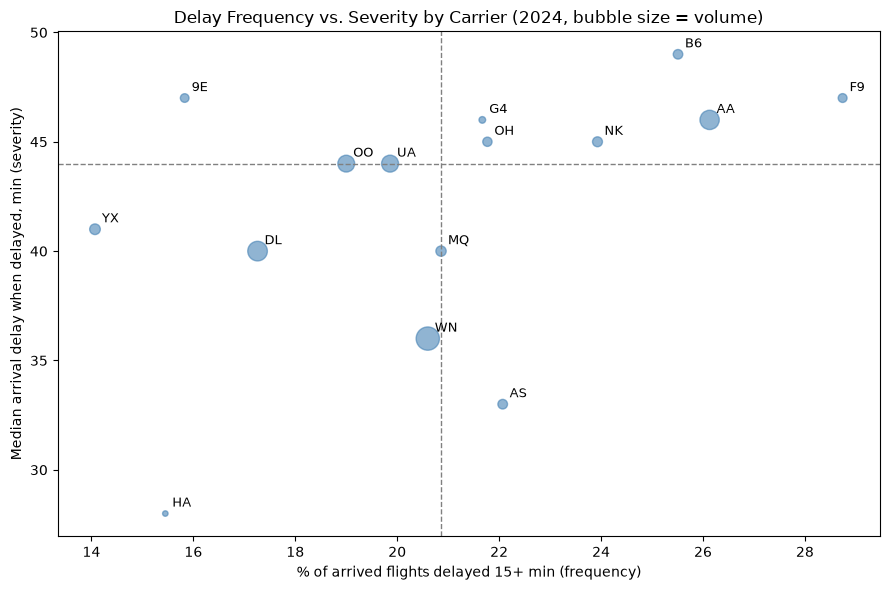

In [16]:
df_freq_sev = df_punctuality_by_carrier.merge(df_severity_by_carrier, on="reporting_airline")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df_freq_sev["pct_delayed"], df_freq_sev["median_delay_when_delayed"],
           s=df_freq_sev["arrived_flights"] / 5000, alpha=0.6, color="steelblue")

for _, row in df_freq_sev.iterrows():
    ax.annotate(row["reporting_airline"], (row["pct_delayed"], row["median_delay_when_delayed"]),
                xytext=(5, 5), textcoords="offset points", fontsize=9)

ax.axvline(df_freq_sev["pct_delayed"].median(), color="gray", linestyle="--", linewidth=1)
ax.axhline(df_freq_sev["median_delay_when_delayed"].median(), color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("% of arrived flights delayed 15+ min (frequency)")
ax.set_ylabel("Median arrival delay when delayed, min (severity)")
ax.set_title("Delay Frequency vs. Severity by Carrier (2024, bubble size = volume)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_frequency_vs_severity.png", dpi=150)
plt.show()

Most carriers sit in a narrow band once a delay happens: the median delay among delayed flights is 40 to 49 minutes for twelve of the fifteen. The differences are in the tail. AA's average delay when delayed is 85.7 minutes against a median of 46, so its long delays are what set it apart; on the median it's no worse than F9 (47). On the chart, which uses the median, both sit far to the right because they're late often, but at an ordinary height. AA's long tail only shows up in the mean.

WN's low mean delay from Section 2 comes from short delays rather than few delays. It's late at the national rate, but its delays are among the shortest (median 36 minutes). DL is the opposite case, late less often than most, with delays of ordinary length. AS and HA have the shortest delays of all (medians 33 and 28).

I used the median on the chart because the mean is pulled by the tail: G4 has the highest mean (88.7) with an ordinary median (46).

# 7. Delay propagation along aircraft rotations

Late Aircraft was the largest cause in the Pareto. BTS records it flight by flight, but the mechanism behind it is a sequence: one aircraft (`tail_number`) flies several legs a day, and a late arrival leaves less time for the next turnaround. Window functions let me rebuild those sequences.

For each aircraft and day, flights are ordered by scheduled departure, and `LAG()` brings in the previous leg's arrival delay and destination. Only flights that actually arrived are used (not cancelled, not diverted).

The same aircraft sometimes has two legs with the same scheduled time, and PostgreSQL then orders them arbitrarily, so `LAG()` and `ROW_NUMBER()` could give different results on each run. I break those ties with the actual departure time and then `row_hash`, which makes every run identical.

## 7.1 Checking that the rotations are real

If the sequence is right, the previous leg's destination should be the current leg's origin. A low match rate would mean the reconstruction is unreliable. Some mismatches are expected: removing cancelled flights breaks chains, and overnight flights cross the date boundary used in the partition.

In [17]:
query_rotation_check = """
WITH rotations AS (
    SELECT
        origin,
        LAG(dest) OVER (PARTITION BY tail_number, flight_date ORDER BY crs_dep_time, dep_time, row_hash) AS prev_dest
    FROM staging.stg_bts_flights
    WHERE cancelled = 0
      AND diverted = 0
      AND tail_number IS NOT NULL
)
SELECT
    COUNT(*) AS linked_legs,
    COUNT(*) FILTER (WHERE prev_dest = origin) AS consistent_legs,
    ROUND(100.0 * COUNT(*) FILTER (WHERE prev_dest = origin) / COUNT(*), 2) AS pct_consistent
FROM rotations
WHERE prev_dest IS NOT NULL;
"""

with engine.connect() as conn:
    df_rotation_check = pd.read_sql(text(query_rotation_check), conn)

df_rotation_check

,linked_legs,consistent_legs,pct_consistent
0,5242921,5180216,98.8


98.80% of linked legs are consistent (5,180,216 of 5,242,921): the previous flight of the same aircraft landed where the next one departs, so the reconstruction is reliable. The 1.2% that don't match are left out of Section 7.3.

## 7.2 Delay by position in the aircraft's day

`ROW_NUMBER()` numbers each aircraft's legs within the day. If delays accumulate, later legs should depart later on average.

In [18]:
query_delay_by_leg = """
WITH rotations AS (
    SELECT
        dep_delay,
        ROW_NUMBER() OVER (PARTITION BY tail_number, flight_date ORDER BY crs_dep_time, dep_time, row_hash) AS leg_of_day
    FROM staging.stg_bts_flights
    WHERE cancelled = 0
      AND diverted = 0
      AND tail_number IS NOT NULL
)
SELECT
    leg_of_day,
    COUNT(*) AS flights,
    ROUND(AVG(dep_delay)::numeric, 2) AS avg_dep_delay,
    ROUND(100.0 * AVG(CASE WHEN dep_delay >= 15 THEN 1 ELSE 0 END)::numeric, 2) AS pct_dep_delayed_15
FROM rotations
GROUP BY leg_of_day
HAVING COUNT(*) >= 1000
ORDER BY leg_of_day;
"""

with engine.connect() as conn:
    df_delay_by_leg = pd.read_sql(text(query_delay_by_leg), conn)

df_delay_by_leg

,leg_of_day,flights,avg_dep_delay,pct_dep_delayed_15
0,1,1722326,7.34,11.96
1,2,1593310,10.74,18.38
2,3,1361378,13.30,22.25
3,4,1086430,15.82,26.00
4,5,658693,18.17,28.82
5,6,385447,18.87,29.21
6,7,105343,22.27,32.38
7,8,41808,21.12,28.28
8,9,5665,21.56,25.07
9,10,2877,10.25,18.14


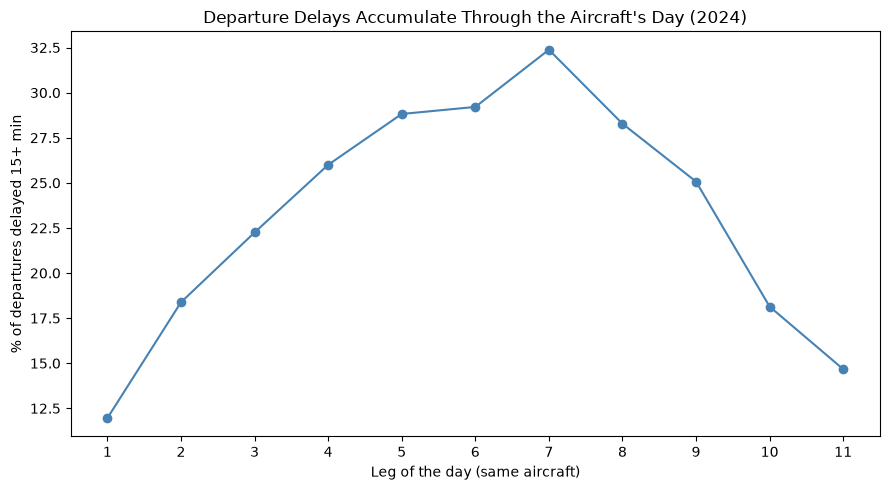

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df_delay_by_leg["leg_of_day"], df_delay_by_leg["pct_dep_delayed_15"], marker="o", color="steelblue")
ax.set_xlabel("Leg of the day (same aircraft)")
ax.set_ylabel("% of departures delayed 15+ min")
ax.set_title("Departure Delays Accumulate Through the Aircraft's Day (2024)")
ax.set_xticks(df_delay_by_leg["leg_of_day"])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_delay_by_leg_of_day.png", dpi=150)
plt.show()

The share of delayed departures climbs steadily through the aircraft's day, from 11.96% on the first leg to 32.38% on the seventh, and the average departure delay triples (7.3 to 22.3 minutes). After the eighth leg the curve drops, but with fewer than 6,000 flights each, those legs are rare and probably a different kind of operation. I don't read much into them.

Leg number and time of day move together, since later legs also depart later. Section 9.1 looks at the hour on its own. The aircraft also change along the curve. Only some planes fly six or seven legs a day, so the later points describe a smaller and different group of aircraft, and part of the rise may come from that.

## 7.3 How much of an incoming delay passes to the next flight

Here each flight is grouped by how late its aircraft arrived on the previous leg. `pass_through_ratio` divides the average departure delay of the next leg by the average incoming delay. A value near 1 means the turnaround absorbed almost nothing; a value well below 1 means ground operations recovered part of it. I leave the ratio empty for the first group: those aircraft arrived early on average, so dividing by a negative incoming delay gives a number with no meaning.

In [20]:
query_delay_propagation = """
WITH rotations AS (
    SELECT
        origin,
        dep_delay,
        LAG(arr_delay) OVER w AS prev_arr_delay,
        LAG(dest) OVER w AS prev_dest
    FROM staging.stg_bts_flights
    WHERE cancelled = 0
      AND diverted = 0
      AND tail_number IS NOT NULL
    WINDOW w AS (PARTITION BY tail_number, flight_date ORDER BY crs_dep_time, dep_time, row_hash)
),
linked AS (
    SELECT
        dep_delay,
        prev_arr_delay,
        CASE
            WHEN prev_arr_delay < 15 THEN '1. under 15 min'
            WHEN prev_arr_delay < 30 THEN '2. 15-29 min'
            WHEN prev_arr_delay < 60 THEN '3. 30-59 min'
            WHEN prev_arr_delay < 120 THEN '4. 60-119 min'
            ELSE '5. 120+ min'
        END AS incoming_delay_bucket
    FROM rotations
    WHERE prev_arr_delay IS NOT NULL
      AND prev_dest = origin
)
SELECT
    incoming_delay_bucket,
    COUNT(*) AS flights,
    ROUND(AVG(prev_arr_delay)::numeric, 1) AS avg_incoming_delay,
    ROUND(AVG(dep_delay)::numeric, 1) AS avg_next_dep_delay,
    ROUND(100.0 * AVG(CASE WHEN dep_delay >= 15 THEN 1 ELSE 0 END)::numeric, 1) AS pct_next_dep_delayed_15,
    CASE
        WHEN incoming_delay_bucket = '1. under 15 min' THEN NULL
        ELSE ROUND((AVG(dep_delay) / NULLIF(AVG(prev_arr_delay), 0))::numeric, 2)
    END AS pass_through_ratio
FROM linked
GROUP BY incoming_delay_bucket
ORDER BY incoming_delay_bucket;
"""

with engine.connect() as conn:
    df_delay_propagation = pd.read_sql(text(query_delay_propagation), conn)

df_delay_propagation

,incoming_delay_bucket,flights,avg_incoming_delay,avg_next_dep_delay,pct_next_dep_delayed_15,pass_through_ratio
0,1. under 15 min,4241911,-9.9,3.9,11.8,NaN
1,2. 15-29 min,352835,21.0,22.0,54.0,1.04
2,3. 30-59 min,288243,42.0,40.4,81.8,0.96
3,4. 60-119 min,187965,83.3,75.4,89.1,0.90
4,5. 120+ min,109262,201.6,149.1,87.0,0.74


This is consistent with delays carrying over from one leg to the next, which is what the Late Aircraft cause in the Pareto records. When the aircraft arrived less than 15 minutes late, 11.8% of next departures were delayed. With an incoming delay of 15 to 29 minutes, that jumps to 54.0%, and above 30 minutes it passes 80%.

The pass-through ratio stays close to 1 for incoming delays up to an hour (1.04, 0.96, 0.90). On average the turnaround absorbs almost nothing, and the next flight leaves about as late as the plane arrived. Only above 120 minutes does it fall to 0.74, probably because the next scheduled departure is further away or the airline swaps aircraft. That fits with Late Aircraft being 40% of all delay minutes. The table can't separate carry-over from causes that hit both legs at once, though, such as a congested hub or a storm over the same airport.

# 8. Airport bottlenecks: taxi-out time

Taxi-out is the time between leaving the gate and taking off. Long taxi-outs mean queues on the ground, so it works as a proxy for congestion at the departure airport, separate from anything that happens in the air. Only airports with at least 5,000 departures in the year are included.

In [21]:
query_taxi_out = """
WITH airport_taxi AS (
    SELECT
        origin,
        origin_city_name,
        COUNT(*) AS departures,
        AVG(taxi_out) AS avg_taxi_out,
        PERCENTILE_CONT(0.9) WITHIN GROUP (ORDER BY taxi_out) AS p90_taxi_out
    FROM staging.stg_bts_flights
    WHERE cancelled = 0
      AND taxi_out IS NOT NULL
    GROUP BY origin, origin_city_name
    HAVING COUNT(*) >= 5000
)
SELECT
    RANK() OVER (ORDER BY avg_taxi_out DESC) AS congestion_rank,
    origin,
    origin_city_name,
    departures,
    ROUND(avg_taxi_out::numeric, 1) AS avg_taxi_out,
    ROUND(p90_taxi_out::numeric, 1) AS p90_taxi_out
FROM airport_taxi
ORDER BY congestion_rank
LIMIT 15;
"""

with engine.connect() as conn:
    df_taxi_out = pd.read_sql(text(query_taxi_out), conn)

df_taxi_out

,congestion_rank,origin,origin_city_name,departures,avg_taxi_out,p90_taxi_out
0,1,JFK,"New York, NY",121055,26.3,41.0
1,2,EWR,"Newark, NJ",125729,24.3,37.0
2,3,ORD,"Chicago, IL",276267,23.8,37.0
3,4,LGA,"New York, NY",158586,23.5,35.0
4,5,ASE,"Aspen, CO",7372,22.3,39.0
5,6,CLT,"Charlotte, NC",214578,21.7,33.3
6,7,SAN,"San Diego, CA",93434,21.5,32.0
7,8,SEA,"Seattle, WA",161911,21.2,31.0
8,9,PHL,"Philadelphia, PA",98954,21.1,34.0
9,10,JAC,"Jackson, WY",5540,21.0,39.0


Three of the four airports with the longest taxi-out are in the New York area (JFK 26.3 min, EWR 24.3, LGA 23.5), with Chicago O'Hare in between (23.8). Large hubs with crowded airspace and runways were the expected result. One in ten JFK departures waits 41 minutes or more between gate and takeoff.

Two small mountain airports also make the list, Aspen (ASE) and Jackson Hole (JAC), each with fewer than 7,500 departures but 90th percentiles close to JFK's. Winter operations such as de-icing are a likely factor, though I haven't checked it by month. JAC is also one of the worst routes from Section 2, so there the ground delay adds to the route problem. Otherwise, hub congestion and the worst routes look like separate problems.

# 9. Time patterns: scheduled hour and disruption days

Two quick operational cuts using the time fields. This isn't a trend analysis; the point is to locate when problems concentrate.

## 9.1 Delay rate by scheduled departure hour

`crs_dep_time` is stored as HHMM, so integer division by 100 gives the scheduled hour.

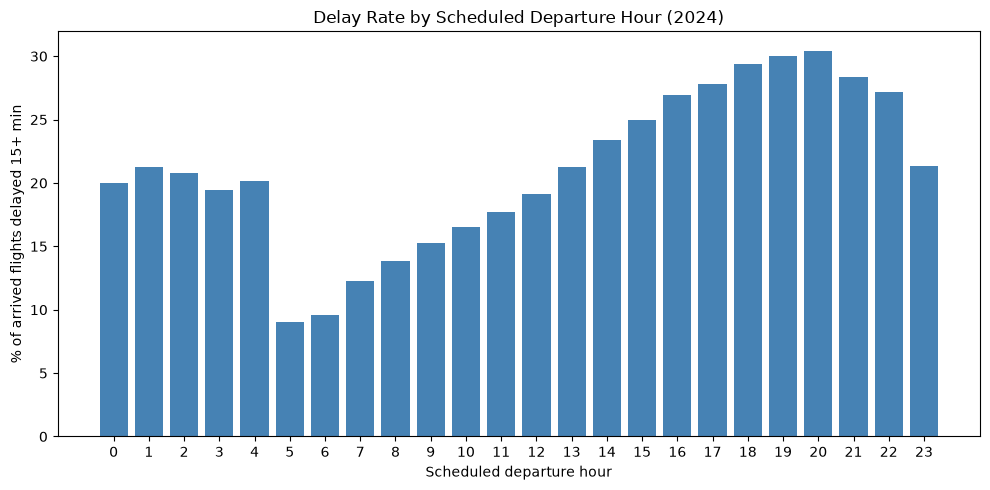

,sched_dep_hour,arrived_flights,pct_delayed
0,0,12102,20.02
1,1,4001,21.27
2,2,1511,20.78
3,3,1069,19.46
4,4,526,20.15
5,5,197159,9.06
6,6,487660,9.58
7,7,486842,12.29
8,8,476025,13.86
9,9,390538,15.30


In [22]:
query_delay_by_hour = """
SELECT
    (crs_dep_time / 100) AS sched_dep_hour,
    COUNT(*) FILTER (WHERE arr_del15 IS NOT NULL) AS arrived_flights,
    ROUND(100.0 * COUNT(*) FILTER (WHERE arr_del15 = 1)
        / NULLIF(COUNT(*) FILTER (WHERE arr_del15 IS NOT NULL), 0), 2) AS pct_delayed
FROM staging.stg_bts_flights
WHERE crs_dep_time < 2400
GROUP BY sched_dep_hour
ORDER BY sched_dep_hour;
"""

with engine.connect() as conn:
    df_delay_by_hour = pd.read_sql(text(query_delay_by_hour), conn)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(df_delay_by_hour["sched_dep_hour"], df_delay_by_hour["pct_delayed"], color="steelblue")
ax.set_xlabel("Scheduled departure hour")
ax.set_ylabel("% of arrived flights delayed 15+ min")
ax.set_title("Delay Rate by Scheduled Departure Hour (2024)")
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_delay_rate_by_hour.png", dpi=150)
plt.show()

df_delay_by_hour

The delay rate rises through the day almost without a break: 9.06% for flights scheduled at 5 a.m., 30.44% at 8 p.m., then it eases off late at night. Early flights leave with aircraft that spent the night at the gate, while evening flights inherit everything that went wrong earlier. It's the propagation from Section 7 seen from the clock.

The hours between midnight and 4 a.m. have few flights, so I don't read much into them. The query also leaves out a single flight with a `crs_dep_time` of 2400, the value BTS uses for midnight, which would otherwise show up as an hour 24 with one flight.

## 9.2 The most disrupted days of 2024

A daily cancellation rate, compared with the yearly average through a window function, flags the days where the system broke down. `cancellation_code` shows which cause dominated each day (A = carrier, B = weather, C = NAS).

In [23]:
query_disruption_days = """
WITH daily AS (
    SELECT
        flight_date,
        COUNT(*) AS scheduled,
        COUNT(*) FILTER (WHERE cancelled = 1) AS cancelled,
        COUNT(*) FILTER (WHERE cancellation_code = 'A') AS canc_carrier,
        COUNT(*) FILTER (WHERE cancellation_code = 'B') AS canc_weather,
        COUNT(*) FILTER (WHERE cancellation_code = 'C') AS canc_nas
    FROM staging.stg_bts_flights
    GROUP BY flight_date
),
daily_rates AS (
    SELECT
        *,
        100.0 * cancelled / scheduled AS pct_cancelled,
        AVG(100.0 * cancelled / scheduled) OVER () AS yearly_avg_pct
    FROM daily
)
SELECT
    flight_date,
    TO_CHAR(flight_date, 'Dy') AS weekday,
    scheduled,
    cancelled,
    ROUND(pct_cancelled, 2) AS pct_cancelled,
    ROUND(pct_cancelled / yearly_avg_pct, 1) AS times_yearly_avg,
    CASE GREATEST(canc_carrier, canc_weather, canc_nas)
        WHEN canc_carrier THEN 'Carrier'
        WHEN canc_weather THEN 'Weather'
        ELSE 'NAS'
    END AS main_cancellation_cause
FROM daily_rates
ORDER BY pct_cancelled DESC
LIMIT 10;
"""

with engine.connect() as conn:
    df_disruption_days = pd.read_sql(text(query_disruption_days), conn)

df_disruption_days

,flight_date,weekday,scheduled,cancelled,pct_cancelled,times_yearly_avg,main_cancellation_cause
0,2024-07-19,Fri,21468,3548,16.53,12.2,Carrier
1,2024-01-15,Mon,18620,2962,15.91,11.8,Weather
2,2024-01-16,Tue,16530,2111,12.77,9.4,Weather
3,2024-08-04,Sun,21099,2288,10.84,8.0,Weather
4,2024-07-20,Sat,19169,2048,10.68,7.9,Carrier
5,2024-01-12,Fri,18590,1936,10.41,7.7,Weather
6,2024-07-21,Sun,21117,2132,10.10,7.5,Carrier
7,2024-10-10,Thu,21539,2027,9.41,7.0,Weather
8,2024-10-09,Wed,19334,1677,8.67,6.4,Weather
9,2024-07-22,Mon,21430,1761,8.22,6.1,Carrier


The worst day of 2024 was 19 July, with 16.53% of flights cancelled, 12 times the yearly average, and carrier as the main cause. That's the CrowdStrike IT outage, and its tail shows up on 20, 21 and 22 July, all carrier-driven. Four of the ten worst days belong to that one event.

The rest are weather: the January storms (12, 15 and 16 January), 4 August, when Tropical Storm Debby was approaching Florida, and 9 and 10 October, which match Hurricane Milton's landfall. Hurricane Helene in late September doesn't reach the top ten.

# 10. Conclusions

One flight in five that reached its destination arrived 15+ minutes late (20.82%), and 1.36% of scheduled flights were cancelled.

The clearest finding is how delays travel. Late Aircraft is the largest cause of delay minutes (40.4%), and following each aircraft through its day fits that picture. An incoming delay of 15 minutes or more makes the next departure late more than half the time, turnarounds absorb almost none of it, and the delay rate climbs from 12% on the first leg to 32% by the seventh. Seen by the clock, the same pattern goes from 9% of flights delayed at 5 a.m. to 30% at 8 p.m.

Among carriers, F9 and AA are late most often. AA also has the longest tail of delays (85.7 minutes on average once delayed, against a median of 46), while F9's delays are of ordinary length. Once single-carrier routes are removed, AA is still the worst carrier on about 1.7 times its expected share of contested routes. That correction mattered: my first version ranked carriers on every route, and monopoly routes inflated AA's apparent dominance. DL is the most reliable of the large carriers, and WN's low average comes from short delays, not from being late less often.

The worst routes, mostly from small mountain and resort airports into hubs, turned out not to be a weather story. Weather and NAS together explain less of their delay than the national average, and late aircraft and carrier causes dominate. On most of them the typical flight is close to on time and a few extreme delays inflate the average, although EGE→MIA and RDM→DFW are late on a typical day too.

Ground congestion concentrates in the New York airports and O'Hare. And the year's worst disruption had nothing to do with weather: the CrowdStrike outage of July 2024 accounts for four of the ten days with the most cancellations.